# Characteristics for linear transport

**Source:** CompSci §6.1, pp. 59–61 · [Source map](../docs/SOURCES.md) · [Course index](../README.md)

For $f_t+v(x,t)f_x=0$, choose curves $X'=v(X,t)$. The chain rule gives $d f(X,t)/dt=0$. For constant $v$, $X=a+vt$ and $f(x,t)=f_0(x-vt)$. For $v=x\sin t$, integration gives $X=a e^{1-\cos t}$, including the stationary curve $a=0$. Inverting the map gives $f(x,t)=1+[1+(xe^{\cos t-1})^2]^{-1}$ for the lecture initial profile. The transported value is constant, but $\int f\,dx$ need not be conserved for variable velocity in this non-conservative equation.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.22,
                     "axes.spines.top": False, "axes.spines.right": False})
root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "01_Foundations").is_dir() and (p / "requirements.txt").is_file())
out = root / "assets" / "figures"
out.mkdir(parents=True, exist_ok=True)

def show(fig, name):
    fig.tight_layout()
    fig.savefig(out / (name + ".png"), dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

Matplotlib is building the font cache; this may take a moment.


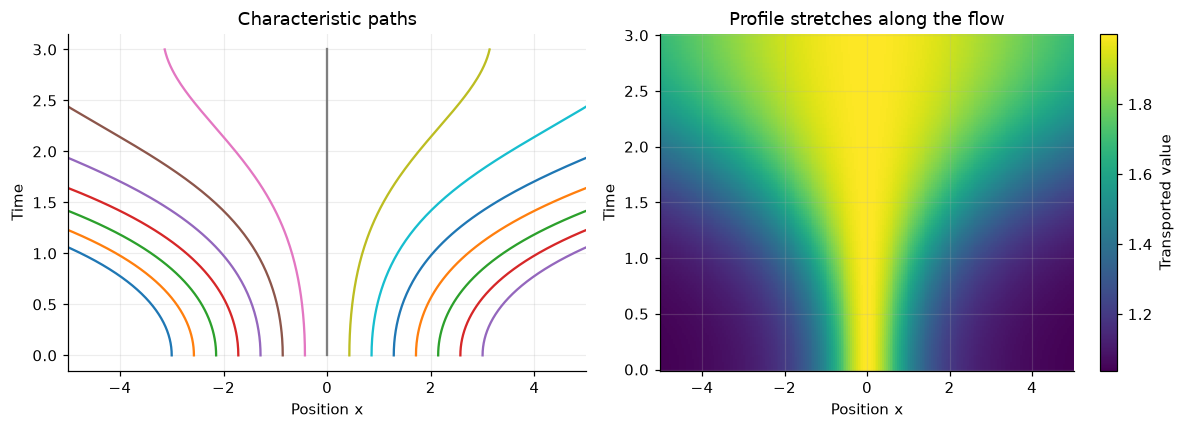

In [2]:
t=np.linspace(0,3,150); x=np.linspace(-5,5,220)
def f0(a): return 1+1/(1+a*a)
def value(x,t): return f0(x*np.exp(np.cos(t)-1))
fig,ax=plt.subplots(1,2,figsize=(11,4))
for a in np.linspace(-3,3,15):
    X=a*np.exp(1-np.cos(t)); ax[0].plot(X,t)
    assert np.allclose(value(X,t),f0(a))
ax[0].set(xlim=(-5,5),xlabel="Position x",ylabel="Time",title="Characteristic paths")
im=ax[1].pcolormesh(x,t,value(x[None,:],t[:,None]),shading="auto",cmap="viridis")
fig.colorbar(im,ax=ax[1],label="Transported value")
ax[1].set(xlabel="Position x",ylabel="Time",title="Profile stretches along the flow")
show(fig,"10-characteristics")
assert np.allclose(value(x,0),f0(x))

## Worked exercise

**Find the initial label of the characteristic through $(x,t)$.** Divide by the expansion factor to obtain $a=xe^{\cos t-1}$. It works for negative and zero labels as well.